# 01. Eksploracja danych w celu przygotowania prognoz cen na Rynku Dnia Następnego

**Autor:** Damian Urbański

**Cel analizy**

Celem analizy jest zbadanie zmienności cen energii elektrycznej w Polsce oraz ocena w jakim stopniu informacje o generacji OZE mogą pomóc w prognozowaniu cen. Analiza wykorzystuje dane godzinowe pochodzące z PSE/TGE oraz dane rzeczywistej i prognozowanej generacji farm wiatrowych i fotowoltaicznych.

| Informacja | Wartość |
| :--- | :---: |
| Okres danych | 2026-08-02 : 2026-10-07 |
| Zmienna docelowa | cena Fixing I |
| Liczba obserwacji | 1608 |
| Żródło danych | PSE oraz TGE |
| Obsługa zmiennych czasowych | UTC | 

## Importy i konfiguracja środowiska

In [188]:
from datetime import datetime, timedelta
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.stattools import adfuller

from utils.db import EnergyDatabase

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: "%.2f" % x)

warnings.filterwarnings("ignore")

plt.rcParams.update(
    {
        "figure.figsize": (14, 6), 
        "figure.dpi": 100,  
        "axes.titlesize": 14,  
        "axes.titleweight": "bold", 
        "axes.labelsize": 12,  
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 11,
        "figure.autolayout": (
            True
        ),
    }
)
START_DATE = "2026-08-01"
END_DATE = "2026-10-07"
TARGET = "fixing_1_pln_mwh"
RANDOM_STATE = 42

energy_db = EnergyDatabase()

## Analiza danych

In [189]:
df = energy_db.fetch_by_datetime("forecasts_and_real", 
                                   columns=["datetime_utc", "pv_fcst_pse", "wind_fcst_pse", "demand_fcst_pse", "exchange_fcst_pse", "resload_fcst_pse", "fixing_1_pln_mwh",
                                            "pv_actual_pse", "wind_actual_pse", "demand_actual_pse", "exchange_actual_pse", "resload_actual_pse",], 
                                   start_date = START_DATE, 
                                   end_date = END_DATE)
df.set_index("datetime_utc", inplace=True)
data = df[["pv_fcst_pse", "wind_fcst_pse", "demand_fcst_pse", "exchange_fcst_pse", "resload_fcst_pse", "fixing_1_pln_mwh"]]

In [190]:
data.isna().sum()

pv_fcst_pse          0
wind_fcst_pse        0
demand_fcst_pse      0
exchange_fcst_pse    0
resload_fcst_pse     0
fixing_1_pln_mwh     0
dtype: int64

In [191]:
data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1608 entries, 2026-08-01 00:00:00+00:00 to 2026-10-06 23:00:00+00:00
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pv_fcst_pse        1608 non-null   float64
 1   wind_fcst_pse      1608 non-null   float64
 2   demand_fcst_pse    1608 non-null   float64
 3   exchange_fcst_pse  1608 non-null   float64
 4   resload_fcst_pse   1608 non-null   float64
 5   fixing_1_pln_mwh   1608 non-null   float64
dtypes: float64(6)
memory usage: 87.9 KB


In [192]:
data.describe()

,pv_fcst_pse,wind_fcst_pse,demand_fcst_pse,exchange_fcst_pse,resload_fcst_pse,fixing_1_pln_mwh
count,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00
mean,3441.28,2432.06,17532.25,-577.29,11658.91,620.76
std,4134.24,1838.10,2686.31,1813.20,3840.19,319.00
min,0.00,41.00,11925.00,-5138.00,2866.00,-41.16
25%,0.00,950.75,15084.38,-1786.25,8622.12,461.60
50%,808.00,1982.50,17750.00,-525.00,11749.00,636.20
75%,7086.00,3535.75,19975.00,542.50,14345.38,762.11
max,13865.00,8148.00,22412.50,4756.00,20556.00,2499.99


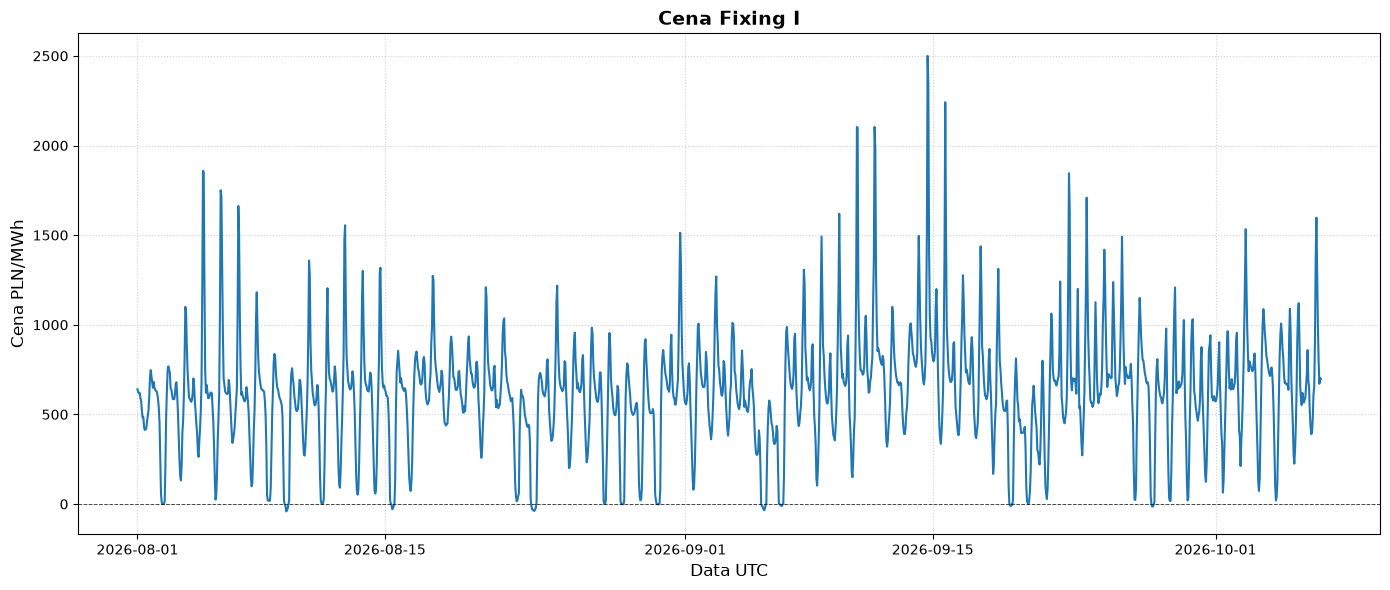

In [193]:
fig, ax = plt.subplots()
ax.plot(data.index, data['fixing_1_pln_mwh'])
ax.set_title("Cena Fixing I")
ax.set_ylabel("Cena PLN/MWh")
ax.set_xlabel("Data UTC")
ax.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth = 0.7,
    alpha=0.7
)
ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

### Test stacjonarności

In [194]:
adf_result = adfuller(data['fixing_1_pln_mwh'].dropna())

print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"p-value: {adf_result[1]:.4e}")
print("Wartości krytyczne:")
for key, value in adf_result[4].items():
    print(f"   {key}: {value:.4f}")

ADF Statistic: -4.0943
p-value: 9.8989e-04
Wartości krytyczne:
   1%: -3.4345
   5%: -2.8634
   10%: -2.5677


$ADF = \text{[-4.0943]}$, $p < 0{,}05$, co pozwala na odrzucenie hipotezy zerowej o obecności pierwiastka jednostkowego. Potwierdza to stacjonarność badanego szeregu wokół średniej i brak konieczności stosowania różnicowania przed modelowaniem.

### Korelacja, skośność i kurtoza

In [195]:
data.kurtosis().sort_values()

demand_fcst_pse     -1.22
pv_fcst_pse         -0.91
resload_fcst_pse    -0.70
exchange_fcst_pse   -0.20
wind_fcst_pse        0.08
fixing_1_pln_mwh     3.12
dtype: float64

In [196]:
data.skew().sort_values()

demand_fcst_pse     -0.23
resload_fcst_pse     0.07
exchange_fcst_pse    0.11
fixing_1_pln_mwh     0.66
pv_fcst_pse          0.77
wind_fcst_pse        0.91
dtype: float64

In [197]:
data.corr()['fixing_1_pln_mwh'].sort_values()

pv_fcst_pse         -0.63
wind_fcst_pse       -0.14
demand_fcst_pse      0.20
exchange_fcst_pse    0.70
resload_fcst_pse     0.89
fixing_1_pln_mwh     1.00
Name: fixing_1_pln_mwh, dtype: float64

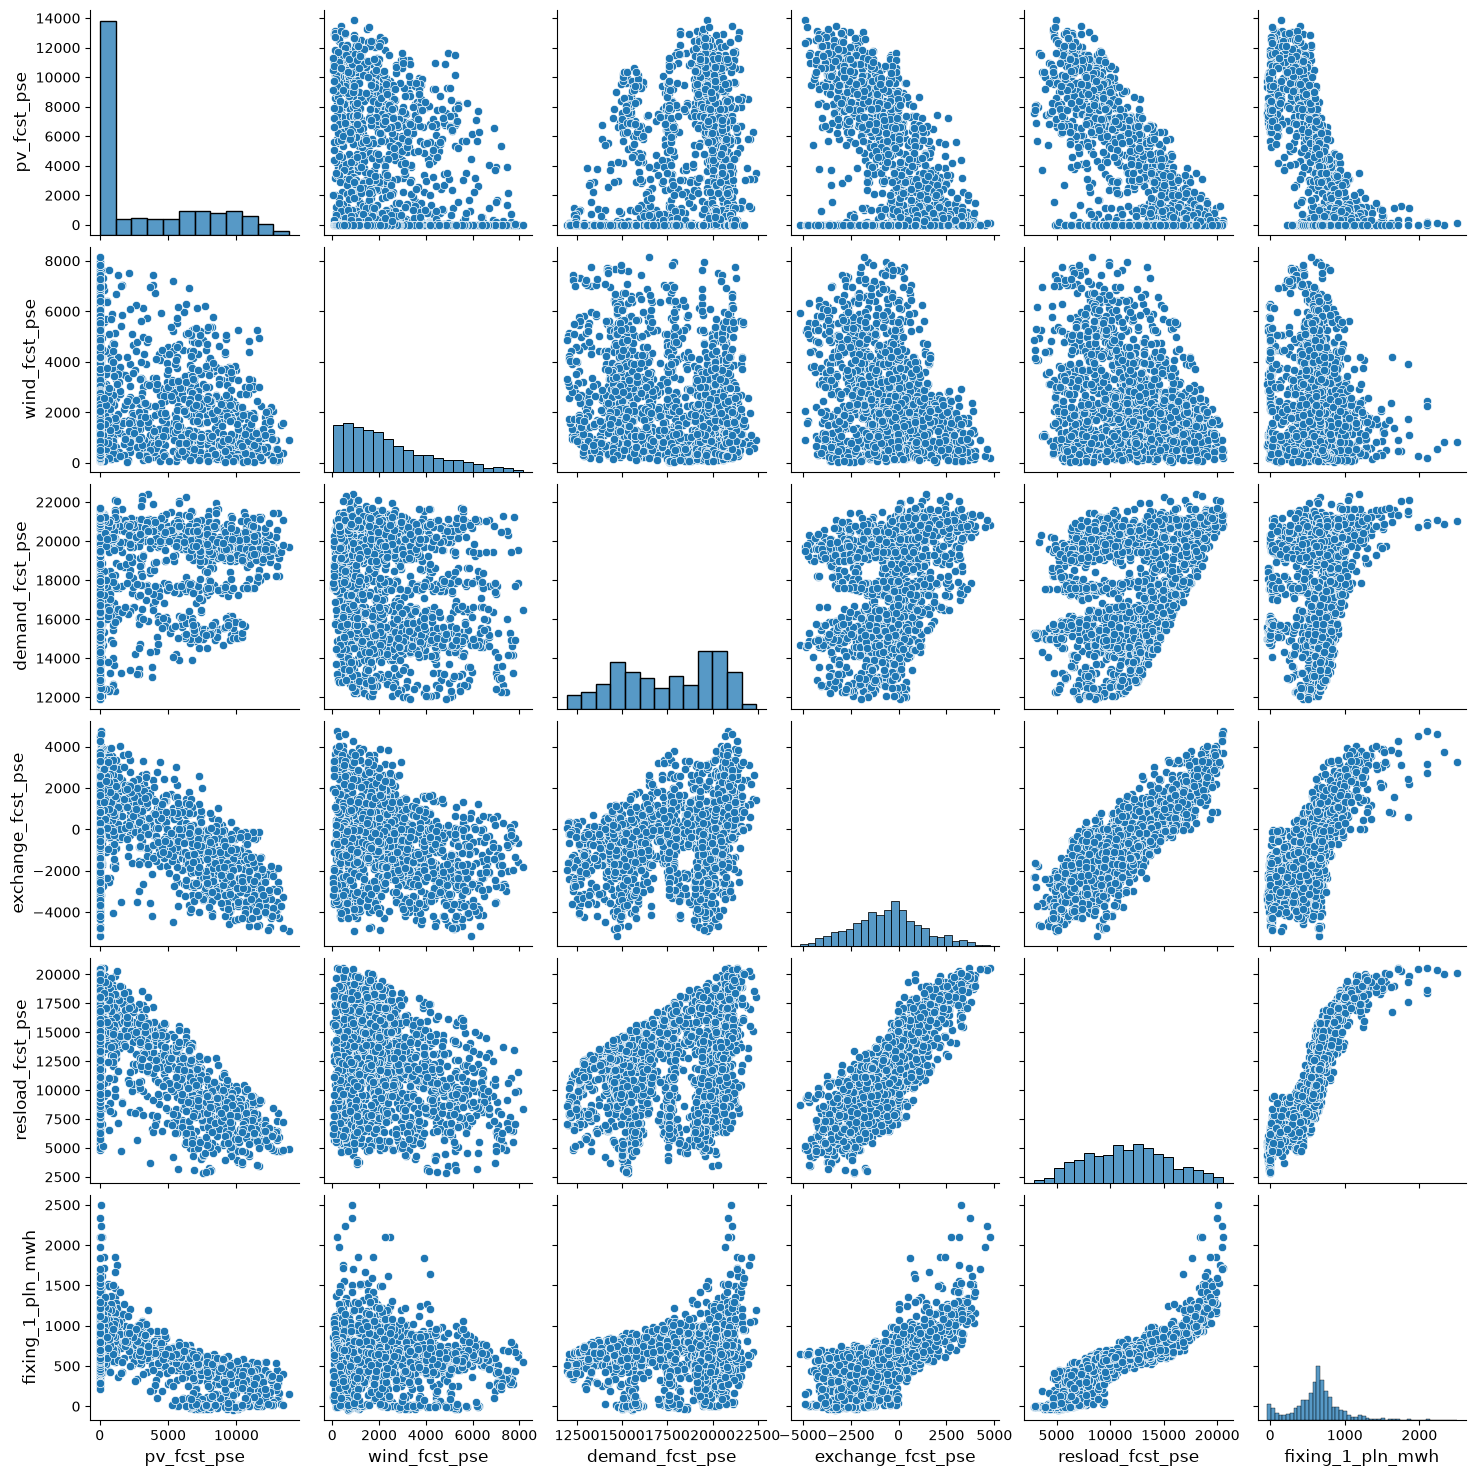

In [198]:
sns.pairplot(data)

| Zmienna | Skośność | Kurtoza | Korelacja z celem | Interpretacja | Wnioski |
| :--- | :---: | :---: | :---: | :--- | :--- |
| **`fixing_1_pln_mwh`** (zmienna celu) | **+0.66** | **+3.12** | **1.00** | Wyraźna leptokurtoza (grube ogony) i prawostronna asymetria. Obecność skrajnych pików cenowych (w godzinach szczytowych). | Wrażliwość na funkcję straty $MSE$. Wskazane użycie $Huber\ Loss$, $MAE$ lub transformacji. |
| **`resload_fcst_pse`** | +0.07 | -0.70 | **+0.89** | Zapotrzebowanie resztkowe ($demand - pv - wind$): moc, którą muszą pokryć jednostki konwencjonalne i wymiana. Rozkład niemal symetryczny, o ujemnej kurtozie (płaski, bez wyraźnego centrum). | Najsilniejszy predyktor liniowy i kluczowa cecha dla modeli nieliniowych. |
| **`demand_fcst_pse`** | -0.23 | -1.22 | **+0.20** | Prognoza zapotrzebowania KSE (`kse-load`), cykl dobowy i tygodniowy. Silnie ujemna kurtoza (płaski rozkład), bo popyt przyjmuje głównie dwa poziomy: noc i dzień/wieczór. | Słaba korelacja liniowa z ceną: samo zapotrzebowanie nie tłumaczy ceny, bo w południe wysoki popyt pokrywa fotowoltaika. Wartość zmiennej ujawnia się w połączeniu z `pv` i `wind` (Z1) lub jako składnik `resload`. |
| **`exchange_fcst_pse`** | +0.11 | -0.20 | **+0.70** | Saldo wymiany międzysystemowej. Dodatnie wartości (import) korelują z wysokimi cenami krajowymi. | Odzwierciedla import droższej/tańszej energii z rynków połączonych. Silnie skorelowana z `resload` (r ≈ 0.83). |
| **`pv_fcst_pse`** | **+0.77** | -0.91 | **-0.63** | Silna asymetria z powodu braku generacji w nocy. Silny efekt merit-order (tłumienie cen w południe). | Wskazane użycie cechy złożonej (np. $PV \times Hour$): może wyjaśnić zjawisko kanibalizacji cenowej. |
| **`wind_fcst_pse`** | **+0.91** | +0.08 | **-0.14** | Prawoskośny rozkład generacji wiatrowej (częste okresy słabego wiatru, rzadziej silne porywy). | Ujemny wpływ na cenę, słabszy liniowo niż PV z uwagi na brak sztywnej cykliczności dobowej. |


- Brak realcji czysto liniowej dla `fixing_1` oraz `resload_fcst_pse`: przy wysokim resload następuje załamanie krzywej w górę z powody włączania najdroższych bloków. Modele liniowe w tym przypadku mogą **systematycznie niedoszacowywać pików cenowych**. **Wskazane użycie nieliniowych algorytmów (GBDT)**
- Wysoka kurtoza zmiennej celu - w przypadku używania MSE lub RMSE jako funkcji straty może to prowadzić do wysokiego penalizowania pojedynczych pików cenowych kosztem dopasowania do profilu. Zalecane są dwie opcje:
    - za metrykę użyć MAE lub/oraz WAPE, a optymalizację przeprowadzić przy użyciu Huber Loss lub Quantile Loss
    - wykonać transformację Inverse Hyperbolic Sine (IHS / $\text{asinh}$) na zmiennej celu

### Wartości odstające

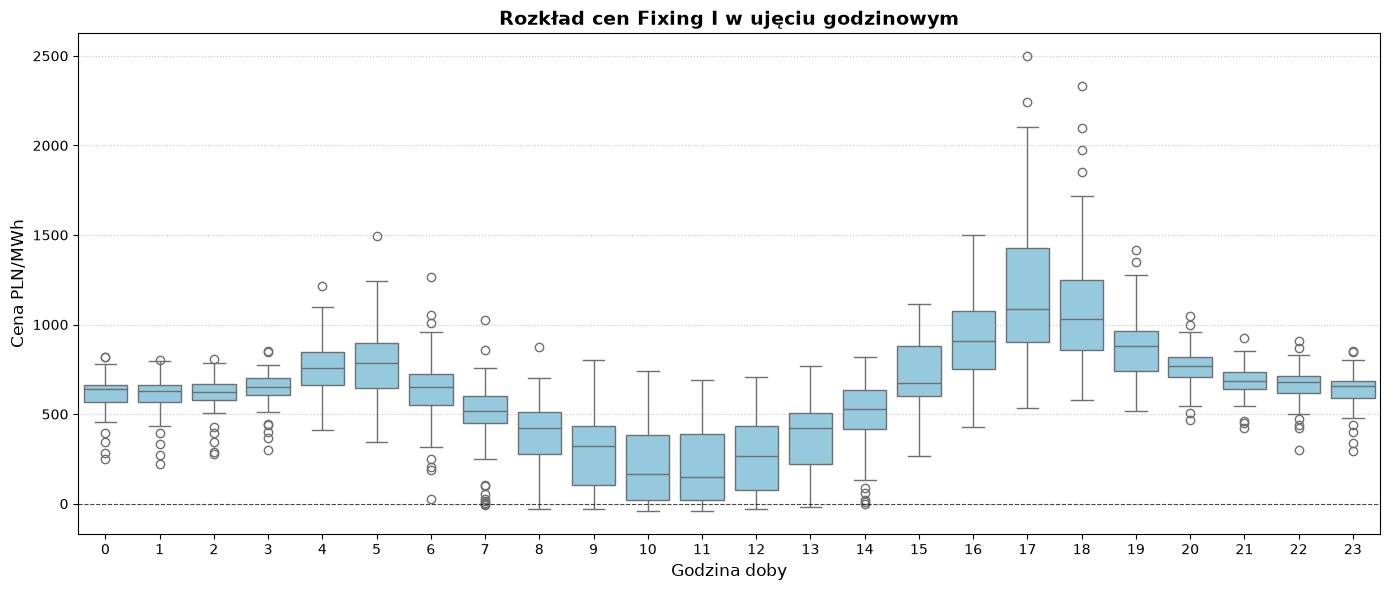

In [199]:
plt.figure()
sns.boxplot(
    data=data,
    x=data.index.hour,
    y='fixing_1_pln_mwh',
    color= 'skyblue',
)
plt.title('Rozkład cen Fixing I w ujęciu godzinowym')
plt.xlabel('Godzina doby')
plt.ylabel('Cena PLN/MWh')
plt.axhline(0, color='black', linestyle='--', linewidth = 0.8, alpha = 0.7)
plt.grid(axis='y', linestyle=':', alpha = 0.7)
plt.show()

Analiza rozkładu cen w ujęciu godzinowym wskazuje na wyraźną eskalację cen oraz wzrost ich zmienności w godzinach popołudniowo-wieczornych (16-19 UTC), ze szczególnym uwzględnieniem godziny 17 UTC. W tym przedziale notuje się najwyższe wartości mediany, najszerszy rozstęp międzykwartylowy oraz ekstrmalne wartości odstające w górę. Świadczy to o dużej niestabilnośic i skokach cenowych w godzinach szczytu zapotrzebowania.

W pozostałych porach dnia obserwuje się stabilizację cen nocą (0–3 i 20–23) z medianą na poziomie 600–800 PLN/MWh, lekki wzrost poranny (4–5) oraz znaczny spadek cen w południe (9–14), wynikający z wysokiej generacji energii z fotowoltaiki.

Zidentyfikowane wartości odstające (do 2500 PLN/MWh) reprezentują realne, ekstremalne zjawiska rynkowe, dlatego nie należy ich usuwać ze zbioru. Dla modeli wrażliwych na outliery (np. liniowych) zaleca się ich przycięcie, natomiast przy algorytmach drzewiastych można pozostawić je w formie surowej.

### Współliniowość cech

In [200]:
y = data['fixing_1_pln_mwh']
X = data.drop(columns=['fixing_1_pln_mwh'])
X_const = sm.add_constant(X)

vif_df = pd.DataFrame({
    'Feature': X.columns,
    'VIF': [variance_inflation_factor(X_const.values, i) for i in range(1, X_const.shape[1])]
}).sort_values(by='VIF', ascending=False).reset_index(drop=True)

vif_df

,Feature,VIF
0,pv_fcst_pse,1000799917193443.50
1,wind_fcst_pse,1000799917193443.50
2,demand_fcst_pse,1000799917193443.50
3,resload_fcst_pse,1000799917193443.50
4,exchange_fcst_pse,3.39


W przygotowaniu modeli należy mieć na uwadze, że zmienna `resload_fcst_pse` jest tak naprawdę kombinacją liniową zmiennych `demand_fcst_pse`, `pv_fcst_pse` oraz `wind_fcst_pse` (co jest również widoczne po współczynniku VIF). Nie zaleca się dodawać wszystkich czterech zmiennych do modelu.

Propozycje zestawu zmiennych:

Propozycje zestawów zmiennych do empirycznej weryfikacji:
* **Wariant 1 (Dekompozycja bez zapotrzebowania resztkowego):** `demand`, `pv`, `wind`, `exchange` – zachowanie odrębnego wpływu słońca i wiatru przy usunięciu wskaźnika resload.
* **Wariant 2 (Czysty Merit Order):** `resload`, `exchange` – maksymalna redukcja wymiarowości do zapotrzebowania pokrywanego przez bloki cieplne.
* **Wariant 3 (Zbalansowany – Resload + Udział OZE):** `resload`, `res_share` (gdzie $\text{res\_share} = \frac{\text{pv} + \text{wind}}{\text{demand}}$), `exchange` – ujęcie skali systemu wraz ze strukturą nasycenia OZE.

In [201]:
feature_sets = {
    "Wariant 1 (Dekompozycja bez resload)": [
        'demand_fcst_pse', 'pv_fcst_pse', 'wind_fcst_pse', 'exchange_fcst_pse'
    ],
    "Wariant 2 (Czysty Merit Order)": [
        'resload_fcst_pse', 'exchange_fcst_pse'
    ],
    "Wariant 3 (Zbalansowany: Resload + Penetracja)": [
        'resload_fcst_pse', 'res_share', 'exchange_fcst_pse'
    ],
}

df_eval = data.copy()
df_eval['res_share'] = (df_eval['pv_fcst_pse'] + df_eval['wind_fcst_pse']) / df_eval['demand_fcst_pse']
 
y = df_eval['fixing_1_pln_mwh'].dropna()

for name, cols in feature_sets.items():
    X = df_eval.loc[y.index, cols].dropna()
    y_aligned = y.loc[X.index]
    
    X_const = sm.add_constant(X)
    
    vif_df = pd.DataFrame({
        'Feature': X.columns,
        'VIF': [variance_inflation_factor(X_const.values, i) for i in range(1, X_const.shape[1])]
    }).sort_values(by='VIF', ascending=False).reset_index(drop=True)

    print(f"------------ {name} -----------")
    display(vif_df)

------------ Wariant 1 (Dekompozycja bez resload) -----------


,Feature,VIF
0,pv_fcst_pse,3.78
1,exchange_fcst_pse,3.39
2,demand_fcst_pse,2.62
3,wind_fcst_pse,1.79


------------ Wariant 2 (Czysty Merit Order) -----------


,Feature,VIF
0,resload_fcst_pse,3.26
1,exchange_fcst_pse,3.26


------------ Wariant 3 (Zbalansowany: Resload + Penetracja) -----------


,Feature,VIF
0,resload_fcst_pse,7.51
1,res_share,4.18
2,exchange_fcst_pse,3.38


* **Wariant 1 (Dekompozycja bez resload):** wszystkie cechy mają $VIF < 4$ (maksymalnie $3.78$ dla `pv_fcst_pse`, $3.39$ dla `exchange_fcst_pse`, $2.62$ dla `demand_fcst_pse`, $1.79$ dla `wind_fcst_pse`). Usunięcie `resload` eliminuje dokładną zależność liniową, zachowując odrębny wpływ popytu, profilu dobowego PV i generacji wiatrowej. Główny wybór dla modeli liniowych.

* **Wariant 2 (Czysty Merit Order):** minimalistyczny zestaw, $VIF = 3.26$ dla obu zmiennych (przy dwóch zmiennych VIF jest symetryczny). Redukuje problem bilansu do zapotrzebowania na jednostki konwencjonalne i wymiany transgranicznej. Benchmark do modeli liniowych.

* **Wariant 3 (Resload + Penetracja):** `resload_fcst_pse` ($7.51$), `res_share` ($4.18$), `exchange_fcst_pse` ($3.38$). Żadna zmienna nie przekracza progu $VIF > 10$, ale `resload` przekracza łagodniejszy próg $VIF > 5$. Wynika to z zależności fizycznej: wzrost udziału OZE bezpośrednio obniża zapotrzebowanie resztkowe. Zestaw jest dopuszczalny dla modeli liniowych z regularyzacją, a dla GBDT współliniowość nie stanowi problemu, więc zostaje w nich głównym zastosowaniem.

### Autokorelacja zmiennej celu

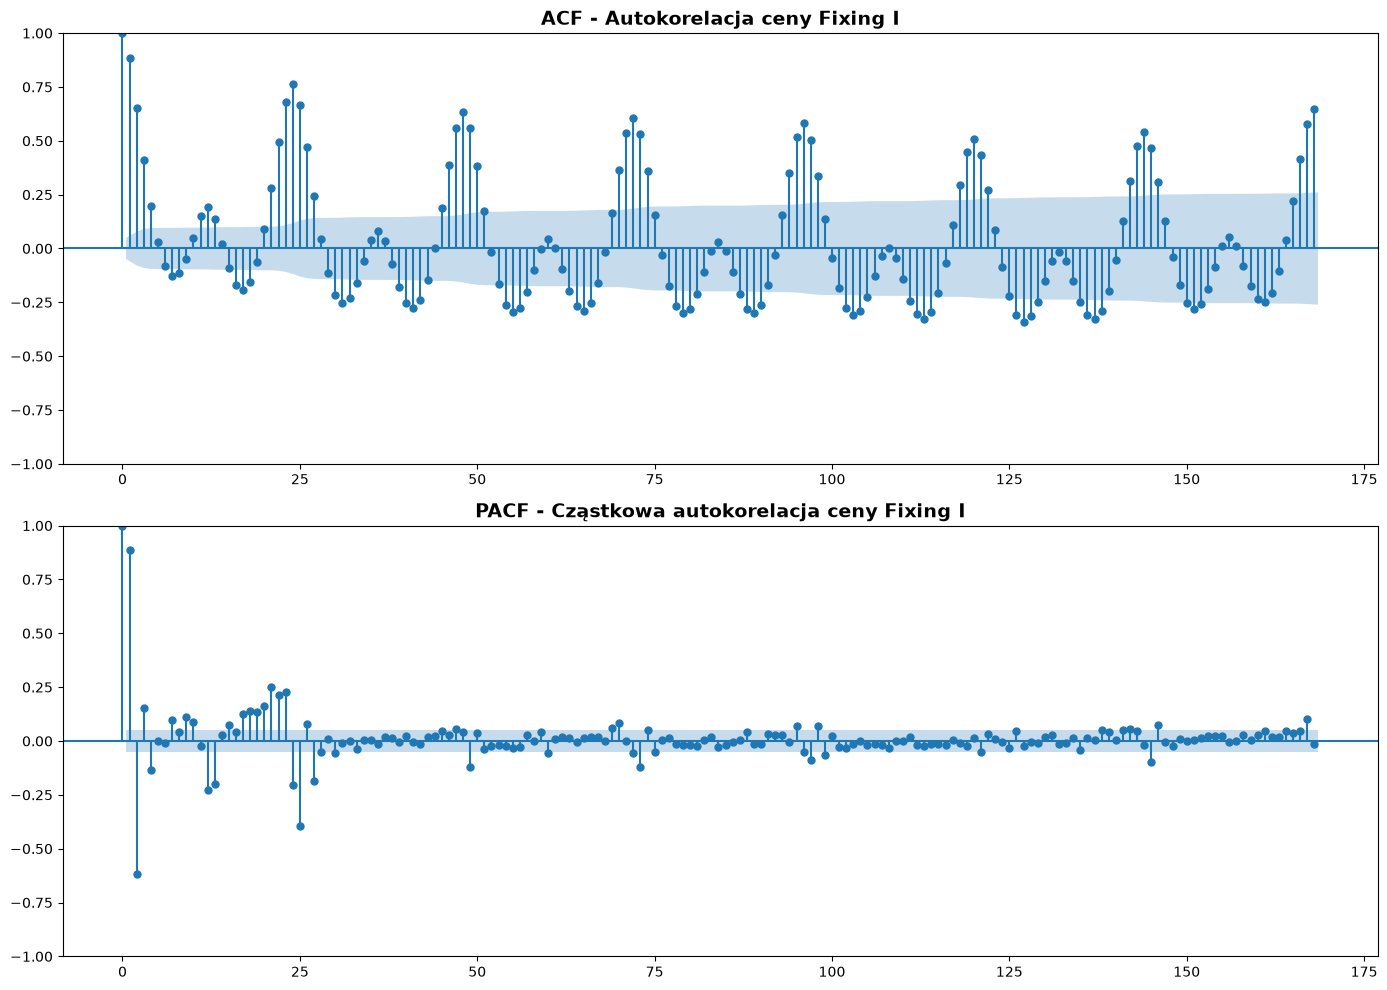

In [202]:
fig, axes = plt.subplots(2,1, figsize=(14,10))
sm.graphics.tsa.plot_acf(data['fixing_1_pln_mwh'], lags = 168, ax=axes[0], title= "ACF - Autokorelacja ceny Fixing I")
sm.graphics.tsa.plot_pacf(data['fixing_1_pln_mwh'], lags=168, ax=axes[1], title="PACF - Cząstkowa autokorelacja ceny Fixing I")
plt.tight_layout()
plt.show()

Wykres ACF wskazuje na wyraźną sezonowość danych - widoczna jest regularna fala z lokalnymi maksimami co 24h (cena o danej godzinie silnie zależy od ceny o tej samej porze w poprzednich dniach). Dodatkowo widoczny jest rownież wyraźny szczyt na końcu wykresu (168h) co wskazuje również na zachowanie cyklu tygodniowego.

Wykres PACF wskauje na statycznie istotne, silne zależności dla pierwszych opóźnień (`t-1`, `t-2`). Kolejne wyraźne wybicie poza przedział ufności pojawiają się przy lagach `t-24` oraz `t-25` co potwierdzania istnienie bezpośredniej zależności can z poprzedniej doby. Dla opóźnień rzędu `t-48`, `t-72`, `t-96`, ... , `t-168` pojawia się minimalna korelacja wykraczająca poza przedział ufności. 

**Rekomendacja**
- Ze względu na horyzont prognozy (składnanie ofert na 24h do wprzód przed zamknięciem bramki aukcyjnej) wartości `t-1` oraz `t-2` nie są jeszcze dostepne, co naturalnie wyklucza możliwość wykorzystania tych opóźnień w modelowaniu
- Zaleca się włączenie opóźnienia dobowego `t-24` jako dominującej zmiennej odzwierciedlającej poziom cen z analogicznej godziny poprzedniej doby
- Mimo że opóźnienia rzędu `t-48`, `t-72`, `t-96`, ... , `t-168` delikatnie wykraczają poza przedział ufności, zaleca się pominięcie tych wartości ze względu na ograniczona próbę (dane z zaledwie 2 miesięcy)
- Dane wykazują również cykliczność tygodniową, ale zamiast dodawać opóźnienia cenowe (`t-168`), które skutkowałyby utratą całego tygodnia obserwacji początkowych, rekomenduje się modelowanie profilu tygodniowego za pomocą deterministycznych cech kalendarzowych (dzień tygodnia, flaga weekendowa).

## Konkluzja - roadmapa do etapu modelowania

### Zestawy zmiennych

**Wspólna baza dla każdego zestawu**

| Cecha | Opis |
| :--- | :--- |
| `price_lag_24` | cena z tej samej godziny poprzedniej doby (znana przed bramką aukcyjną D-1) |
| `sin_d{k}`, `cos_d{k}`, k = 1, 2, 3 | cykl dobowy: `sin(2πk·h/24)`, `cos(2πk·h/24)`, gdzie `h` to godzina czasu lokalnego (z ułamkiem). k=1 to cykl 24 h, k=2 to 12 h, k=3 to 8 h; kolejne harmoniczne pozwalają odwzorować profil z dwoma szczytami i południowym spadkiem |
| `sin_w`, `cos_w` | cykl tygodniowy: `sin(2π·t/168)`, `cos(2π·t/168)`, gdzie `t` to godzina od początku tygodnia |
| `is_weekend` | sobota lub niedziela |
| `is_holiday` | święto ustawowe w Polsce (biblioteka `holidays`) |
| `is_day_off` | `is_weekend` lub `is_holiday` |

Znaczniki czasu są liczone w czasie lokalnym (`Europe/Warsaw`), a przechowywane w UTC.
Cykl tygodniowy jako sinusoida nie odwzoruje skoku „dzień roboczy → weekend", dlatego dodatkowo są flagi dni wolnych.
Modele liniowe dostają dodatkowo interakcję `price_lag_24 × is_day_off` (lag z niedzieli opisuje poniedziałek inaczej niż lag z wtorku).

**Zestawy cech**

| Zestaw | Cechy fundamentalne (poza bazą) | VIF (max) | Cel zestawu |
| :--- | :--- | :---: | :--- |
| **Z0** | brak (tylko baza) | n/d | punkt odniesienia: ile wnoszą prognozy PSE ponad kalendarz i lag cenowy |
| **Z1** (dekompozycja) | `demand_fcst`, `pv_fcst`, `wind_fcst`, `exchange_fcst` | 3.78 | główny zestaw dla modeli liniowych, osobny wpływ popytu, słońca i wiatru; w modelach liniowych zawiera informację z `resload` (kombinacja liniowa cech) |
| **Z2** (merit order) | `resload_fcst`, `exchange_fcst` | 3.26 | benchmark: cały bilans mocy w jednej zmiennej; dla drzew sprawdza, czy podanie `resload` wprost pomaga względem Z1 |
| **Z3** (resload + penetracja OZE) | `resload_fcst`, `res_share` = (pv + wind) / demand, `exchange_fcst` | 7.51 | umiarkowana współliniowość (VIF > 5, < 10): zestaw dla drzew, a w modelach liniowych tylko z regularyzacją (Ridge); `res_share` dodaje informację o nasyceniu OZE |

Dodatki wyłącznie dla modeli liniowych: w Z1 interakcje `pv_fcst × {sin_d1, cos_d1}`; w Z2 i Z3 `SplineTransformer(resload_fcst, n_knots=5, degree=3)` ze względu na nieliniową zależność cena(resload).

### Proponowane modele

**Benchmarki**

| ID | Benchmark | Reguła |
| :--- | :--- | :--- |
| B0 | Persistence `t-24` | cena o godzinie `h` dnia D = cena o godzinie `h` dnia D-1 |
| B1 | Persistence z typem dnia | j.w. dla wt–pt, ale dla pn, sb, nd bierzemy `t-168` (ta sama godzina tydzień wcześniej), bo poniedziałek po niedzieli to inny rodzaj dnia |


**Modele uczone.**

| ID | Model (implementacja) | Funkcja straty (optymalizowana) | Zestawy | Hiperparametry (mała siatka) |
| :--- | :--- | :--- | :--- | :--- |
| M1 | `Ridge` + `StandardScaler` | L2 (MSE + kara na wagi) | Z0, Z1, Z2, Z3 | `alpha` ∈ logspace(-2, 3, 20) |
| M2 | `HuberRegressor` + `StandardScaler` | Huber | Z1, Z2 | `epsilon` ∈ {1.35, 2.0}, `alpha` ∈ {1e-4, 1e-2, 1} |
| M3 | `LGBMRegressor`, objective `huber` | Huber | Z0, Z1, Z2, Z3 | patrz siatka LightGBM; `alpha` (próg Hubera) ∈ {50, 100} PLN/MWh |
| M4 | `LGBMRegressor`, objective `l1` | MAE | Z1, Z3 | patrz siatka LightGBM |
| M5 | `ExtraTreesRegressor` | L2 | Z1, Z3 | `min_samples_leaf` ∈ {5, 10, 20}, `max_features` ∈ {0.5, 1.0}, 300 drzew |
| M6 | Ensemble: średnia najlepszego modelu liniowego i najlepszego LightGBM | n/d | najlepsze z powyższych | wagi 0.5 / 0.5 |

Siatka LightGBM (płytkie drzewa i silna regularyzacja, bo mamy ok. 67 dni danych):
`num_leaves` ∈ {4, 8}, `learning_rate` ∈ {0.03, 0.1}, `n_estimators` ∈ {200, 400}, `min_child_samples` ∈ {20, 40}, `reg_lambda` ∈ {1, 10}, `subsample` = `colsample_bytree` = 0.8.

Transformacja celu sprawdzana tylko dla najlepszego modelu liniowego i najlepszego LightGBM: surowa cena `y` vs `asinh(y / 100)`
(łagodzi pików, obsługuje ceny ujemne; predykcja jest odwracana przez `100 · sinh(·)`).

Struktura: jeden model globalny dla wszystkich godzin doby (cechy cykliczne niosą informację o godzinie).
Osobne modele na godzinę lub blok doby odrzucone ze względu na zbyt mało obserwacji na model.


### Walidacja prognoz

| Etap | Dni (orientacyjnie) | Do czego służy |
| :--- | :---: | :--- |
| 1. Strojenie | 1–35 | wybór hiperparametrów: `TimeSeriesSplit` po dobach (3 foldy), kryterium MAE; po wyborze hiperparametry są zamrożone |
| 2. Walk-forward | 36–60 | porównanie wszystkich modeli i zestawów |
| 3. Holdout | 61–67 | jednorazowa ocena 1–2 finalistów, bez dalszego strojenia |

### Metryki

| Metryka | Wzór / definicja |
| :--- | :--- |
| **MAE** [PLN/MWh] | średnia z \|ŷ − y\| |
| **RMSE** [PLN/MWh] | pierwiastek ze średniej (ŷ − y)² | 
| **WAPE** | Σ\|ŷ − y\| / Σ\|y\| |
| **rMAE** | MAE modelu / MAE benchmarku B0 |
| **Bias** | średnia z (ŷ − y) |
| **MAE w szczycie** (16–19 UTC) | MAE tylko dla tych godzin |
| **Dzienne MAE: mediana i IQR** | MAE liczone osobno dla każdej doby testowej |

### Ograniczenia



- Ok. 67 dni danych (efektywnie ok. 67 niezależnych obserwacji dobowych, a nie 1608 godzin), więc ryzyko przeuczenia jest wyższe, niż sugeruje liczba wierszy.
- Dryf sezonowy: od sierpnia do października maleje generacja PV, więc końcówka danych ma inny rozkład niż początek; modele drzewiaste nie ekstrapolują poza zakres widziany w treningu.
- W danych jest tylko jedno święto (15.08, sobota), więc model nie nauczy się osobnego efektu świąt; flaga służy zastosowaniu produkcyjnemu.

### Informacja o charakterze danych (źródła i znacznik publikacji)

Prognozy `pv`, `wind` i `exchange` pochodzą z endpointu `pk5l-wp`, a `demand` z endpointu `kse-load` (`load_fcst`, średnia z 4 kwadransów do godziny). 

W zbiorze historycznym znacznik `publication_datetime_utc` (z `pk5l-wp`) jest późniejszy niż godzina dostawy (`plan_dtime_utc`) dla wszystkich 1608 rekordów, a dla każdej godziny dostawy jest dokładnie jedna wersja prognozy. Znacznik publikacji z `kse-load` nie jest zapisywany w bazie, a backfill zwraca ostatnią dostępną wersję, więc nie zweryfikowano, czy `demand` odpowiada wersji sprzed bramki.

Oznacza to, że są to ostatnio zaktualizowane wartości, a nie wersje dostępne w momencie składania ofert.

Wyniki modeli korzystających z prognoz fundamentalnych należy więc traktować jako górne oszacowanie jakości w warunkach produkcyjnych.